In [1]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

import torch.nn as nn 
import torch.optim as optim 

# Đọc file

In [2]:
csv_path = '/kaggle/input/datasets/yesenhuynh/self-driving-car/driving_log.csv'
data_dir = '/kaggle/input/datasets/yesenhuynh/self-driving-car/IMG'

df = pd.read_csv(csv_path)

zero_mask = df['steering'].abs() < 0.01
df = pd.concat([
    df[~zero_mask],
    df[zero_mask].sample(frac=0.25, random_state=42)
]).sample(frac=1.0, random_state=42).reset_index(drop=True)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, shuffle=True)

print(f"Tổng số mẫu : {len(df)}")
print("Số file train : ", len(train_df))
print("Số file test : ", len(test_df))
print(df[:5])

Tổng số mẫu : 3365
Số file train :  2692
Số file test :  673
                                   center  \
0  IMG/center_2026_09_20_20_35_29_576.jpg   
1  IMG/center_2026_09_20_20_29_13_120.jpg   
2  IMG/center_2026_09_20_20_32_38_928.jpg   
3  IMG/center_2026_09_20_20_29_24_108.jpg   
4  IMG/center_2026_09_20_20_28_26_339.jpg   

                                   left  \
0  IMG/left_2026_09_20_20_35_29_576.jpg   
1  IMG/left_2026_09_20_20_29_13_120.jpg   
2  IMG/left_2026_09_20_20_32_38_928.jpg   
3  IMG/left_2026_09_20_20_29_24_108.jpg   
4  IMG/left_2026_09_20_20_28_26_339.jpg   

                                   right  steering  throttle  brake     speed  
0  IMG/right_2026_09_20_20_35_29_576.jpg     -0.35       1.0    0.0  30.16348  
1  IMG/right_2026_09_20_20_29_13_120.jpg      0.00       1.0    0.0  30.19003  
2  IMG/right_2026_09_20_20_32_38_928.jpg      0.30       1.0    0.0  30.16854  
3  IMG/right_2026_09_20_20_29_24_108.jpg      0.00       1.0    0.0  30.18998  
4  IMG/ri

# Tiền xử lý ảnh 

In [3]:
def preprocess_image(image_path):
    img = cv2.imread(image_path) #đọc ảnh
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) #BGR -> RGB
    img = img[60:-25,:,:] #cắt phần trên(bầu trời) và phần dưới(mũi xe)
    img = cv2.resize(img, (200,66)) #reshape ảnh thành kích thước 66x200
    img = img.astype(np.float32)/255.0 #chuẩn hóa về [0,1]
    img = torch.tensor(img).permute(2,0,1) #thay đổi thứ tự (H,W,C)->(C,H,W)
    return img


In [4]:
class SteeringDataset(Dataset):
    def __init__(self, dataframe, data_dir, is_train=False):
        self.df = dataframe.reset_index(drop=True)
        self.data_dir = data_dir
        self.is_train = is_train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx] # lấy hàng thứ idx
        steering_center = float(row['steering']) # giá trị của góc lái
        img_col = 'center' # gán tạm thời
        steering_angle = steering_center 
        if self.is_train:
            choice = np.random.choice(['center', 'left','right'])
            img_col = choice 
            
            if choice == 'left':
                steering_angle = steering_center + 0.2
            else : 
                steering_angle = steering_center - 0.2
        
        img_name = os.path.basename(row[img_col].strip())
        img_path = os.path.join(self.data_dir, img_name)
    
        img = self.preprocess_image(img_path)
            
        if self.is_train and np.random.rand() < 0.5 : 
            img = torch.flip(img,dims=[2])
            steering_angle = -steering_angle
    
        return img, torch.tensor(steering_angle, dtype=torch.float32)
        
    def preprocess_image(self, image_path):
        img = cv2.imread(image_path) #đọc ảnh
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) #BGR -> RGB
        img = img[60:-25,:,:] #cắt phần trên(bầu trời) và phần dưới(mũi xe)
        img = cv2.resize(img, (200,66), interpolation=cv2.INTER_AREA) #reshape ảnh thành kích thước 66x200
        img = img.astype(np.float32)/255.0 #chuẩn hóa về [0,1]
        img = torch.tensor(img).permute(2,0,1) #thay đổi thứ tự (H,W,C)->(C,H,W)
        return img


In [5]:
train_dataset = SteeringDataset(train_df, data_dir=data_dir, is_train=True)
test_dataset = SteeringDataset(test_df, data_dir=data_dir, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

for img, angle in train_loader:
    print("Batch images shape : ", img.shape)
    print("Batch angles shape : ", angle.shape)
    break

Batch images shape :  torch.Size([32, 3, 66, 200])
Batch angles shape :  torch.Size([32])


# Xây dựng Model 

In [6]:
class PilotNet(nn.Module):
    def __init__(self):
        super(PilotNet, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,24,kernel_size=5, stride=2),
            nn.ELU(),
            nn.Conv2d(24,36,kernel_size=5, stride=2),
            nn.ELU(),
            nn.Conv2d(36,48,kernel_size=5, stride=2),
            nn.ELU(),
            nn.Conv2d(48,64,kernel_size=3, stride=1),
            nn.ELU(),
            nn.Conv2d(64,64,kernel_size=3, stride=1),
            nn.ELU()
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*1*18, 116),
            nn.ELU(),
            nn.Linear(116, 50),
            nn.ELU(),
            nn.Linear(50, 10),
            nn.ELU(),
            nn.Linear(10, 1)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x 

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PilotNet().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("Mô hình đã sẵn sàng huấn luyện trên thiết bị : ", device)

Mô hình đã sẵn sàng huấn luyện trên thiết bị :  cuda


In [8]:

import matplotlib.pyplot as plt 

num_epochs = 20  # Số vòng lặp học (có thể tăng lên tùy vào độ lớn của dataset)
train_losses = []
criterion = nn.SmoothL1Loss(beta=0.05)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

cnt = 0 
for epoch in range(num_epochs):
    model.train()  # Chuyển mô hình sang chế độ train
    running_loss = 0.0
    for images, steering_labels in train_loader:
        # Đưa dữ liệu lên GPU/CPU
        images = images.to(device)
        
        steering_labels = steering_labels.to(device).view(-1)
        
        # 1. Xóa gradient cũ
        optimizer.zero_grad()
        
        # 2. Dự đoán góc lái từ ảnh
        outputs = model(images).view(-1)
        
        # 3. Tính toán sai số (Loss)
        loss = criterion(outputs, steering_labels)
         
        # 4. Lan truyền ngược (Backpropagation)
        loss.backward()
        
        # 5. Cập nhật trọng số mạng
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        cnt += 1 
        if cnt % 100 == 0:
            print(f"Đã xong {cnt} batch images")
        
    # Tính loss trung bình của epoch
    epoch_loss = running_loss / len(train_dataset)
    # Thêm vào train_losses 
    train_losses.append(epoch_loss)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {epoch_loss:.6f}")


print("Huấn luyện mô hình hoàn tất!")

# Lưu lại trọng số mô hình sau khi train xong
torch.save(model.state_dict(), 'pilotnet_steering_model.pth')
print("Đã lưu trọng số vào file: pilotnet_steering_model.pth")

Epoch [1/20] - Train Loss: 0.279541
Đã xong 100 batch images
Epoch [2/20] - Train Loss: 0.268638
Đã xong 200 batch images
Epoch [3/20] - Train Loss: 0.235262
Đã xong 300 batch images
Epoch [4/20] - Train Loss: 0.226162
Đã xong 400 batch images
Epoch [5/20] - Train Loss: 0.214164
Đã xong 500 batch images
Epoch [6/20] - Train Loss: 0.215586
Epoch [7/20] - Train Loss: 0.213414
Đã xong 600 batch images
Epoch [8/20] - Train Loss: 0.203071
Đã xong 700 batch images
Epoch [9/20] - Train Loss: 0.197286
Đã xong 800 batch images
Epoch [10/20] - Train Loss: 0.191762
Đã xong 900 batch images
Epoch [11/20] - Train Loss: 0.194318
Đã xong 1000 batch images
Epoch [12/20] - Train Loss: 0.191052
Đã xong 1100 batch images
Epoch [13/20] - Train Loss: 0.189120
Epoch [14/20] - Train Loss: 0.188848
Đã xong 1200 batch images
Epoch [15/20] - Train Loss: 0.186047
Đã xong 1300 batch images
Epoch [16/20] - Train Loss: 0.186863
Đã xong 1400 batch images
Epoch [17/20] - Train Loss: 0.180815
Đã xong 1500 batch images

# Đánh giá 

In [9]:
# Đưa mô hình về chế độ đánh giá (Evaluation mode)
model.eval()
total_test_loss = 0.0
test_losses = []

# Sử dụng torch.no_grad() để tắt việc tính toán gradient, giúp tiết kiệm bộ nhớ và tăng tốc độ
with torch.no_grad():
    for images, steering_labels in test_loader:
        # Chuyển dữ liệu lên thiết bị (GPU/CPU)
        images = images.to(device)
        steering_labels = steering_labels.to(device)
        
        # 1. Dự đoán góc lái từ tập test
        outputs = model(images).squeeze()
        
        # 2. Tính toán sai số (Loss) bằng hàm MSELoss
        loss = criterion(outputs, steering_labels)
        
        # Cộng dồn loss nhân với số lượng mẫu trong batch
        total_test_loss += loss.item() * images.size(0)
test_losses.append(total_test_loss / len(test_dataset))
# Tính trung bình MSE Loss trên toàn bộ tập Test
avg_test_loss = total_test_loss / len(test_dataset)
print(f"Kết quả đánh giá trên tập Test - MSE Loss: {avg_test_loss:.6f}")

Kết quả đánh giá trên tập Test - MSE Loss: 0.165007


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:1074: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.smooth_l1_loss(input, target, reduction=self.reduction, beta=self.beta)


In [10]:
print("Số lượng Epoch (Trục X):", len(range(1, num_epochs + 1)))
print("Độ dài train_losses (Trục Y1):", np.shape(train_losses))
print("Độ dài test_losses (Trục Y2):", np.shape(test_losses))

Số lượng Epoch (Trục X): 20
Độ dài train_losses (Trục Y1): (20,)
Độ dài test_losses (Trục Y2): (1,)


# Vẽ đồ thị 

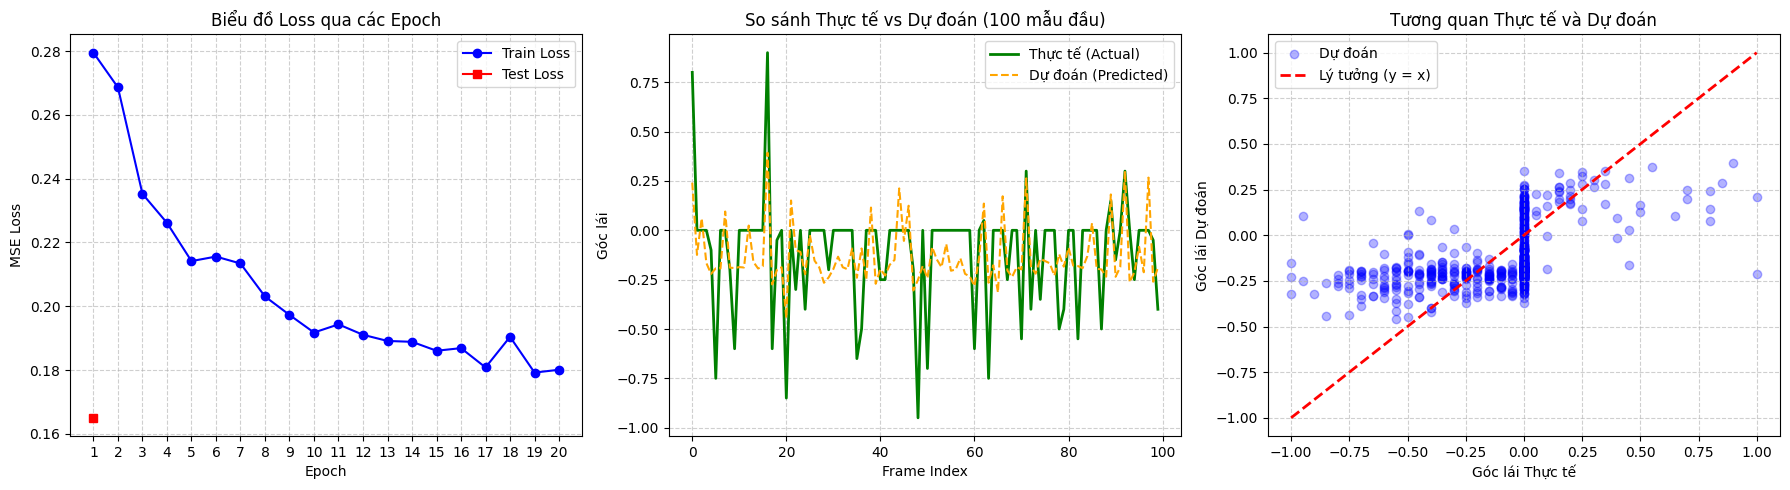

In [11]:
model.eval()
actual_angles = []
predicted_angles = []

with torch.no_grad():
    for images, steering_labels in test_loader:
        images = images.to(device)
        outputs = model(images).view(-1)
        
        actual_angles.extend(steering_labels.cpu().numpy())
        predicted_angles.extend(outputs.cpu().numpy())

actual_angles = np.array(actual_angles)
predicted_angles = np.array(predicted_angles)

# Khởi tạo khung hình chứa 3 biểu đồ
plt.figure(figsize=(18, 5))

# Biểu đồ 1: Loss qua các Epoch (Train vs Test)
plt.subplot(1, 3, 1)
plt.plot(range(1, num_epochs + 1), train_losses, marker='o', label='Train Loss', color='blue')
plt.plot(1 , test_losses, marker='s', label='Test Loss', color='red')
plt.title('Biểu đồ Loss qua các Epoch')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.xticks(range(1, num_epochs + 1))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 2: So sánh Thực tế và Dự đoán (100 mẫu đầu tiên)
plt.subplot(1, 3, 2)
num_samples = min(100, len(actual_angles))
plt.plot(actual_angles[:num_samples], label='Thực tế (Actual)', color='green', linewidth=2)
plt.plot(predicted_angles[:num_samples], label='Dự đoán (Predicted)', color='orange', linestyle='--')
plt.title(f'So sánh Thực tế vs Dự đoán ({num_samples} mẫu đầu)')
plt.xlabel('Frame Index')
plt.ylabel('Góc lái')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 3: Biểu đồ phân tán (Scatter Plot) tương quan toàn tập Test
plt.subplot(1, 3, 3)
plt.scatter(actual_angles, predicted_angles, alpha=0.3, color='blue', label='Dự đoán')
min_val = min(actual_angles.min(), predicted_angles.min())
max_val = max(actual_angles.max(), predicted_angles.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Lý tưởng (y = x)')
plt.title('Tương quan Thực tế và Dự đoán')
plt.xlabel('Góc lái Thực tế')
plt.ylabel('Góc lái Dự đoán')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()